# MPI-INF-3DHP — 2D to 3D Pose Estimation (GPU)
**Architecture:** Deep Residual MLP (4 blocks, 1024 hidden)  
**Input:** 136 (4 cams × 17 joints × 2)  &nbsp;&nbsp; **Output:** 51 (17 joints × 3)  
**Pipeline:** annot.mat → joint mapping → Stage 1 MSE → Stage 2 Anatomy Loss → Eval


In [1]:
# ─── Step 1: Install correct PyTorch for RTX 3060 (CUDA 12.1) ───────────────
import subprocess, sys

print("Uninstalling CPU-only PyTorch if present...")
subprocess.run([sys.executable, "-m", "pip", "uninstall", "torch", "torchvision", "torchaudio", "-y"],
               capture_output=True)

print("Installing PyTorch with CUDA 12.1 support...")
subprocess.run([
    sys.executable, "-m", "pip", "install",
    "torch", "torchvision", "torchaudio",
    "--index-url", "https://download.pytorch.org/whl/cu121", "-q"
], check=True)

print("Installing other dependencies...")
subprocess.run([sys.executable, "-m", "pip", "install", "scipy", "pandas", "matplotlib", "-q"], check=True)

print("\n✅ All packages installed.")


Uninstalling CPU-only PyTorch if present...
Installing PyTorch with CUDA 12.1 support...
Installing other dependencies...

✅ All packages installed.


In [2]:
# ─── Step 2: Verify GPU is detected ─────────────────────────────────────────
import torch

print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
    print(f"VRAM            : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    print("\n✅ GPU ready — training will be fast.")
else:
    print("\n⚠️  CUDA not detected.")
    print("   → In VS Code: Ctrl+Shift+P → 'Select Kernel' → choose your conda/venv with CUDA torch")
    print("   → Or restart VS Code after the pip install above completes.")


PyTorch version : 2.5.1+cu121
CUDA available  : True
GPU             : NVIDIA GeForce RTX 3060 Laptop GPU
VRAM            : 6.4 GB

✅ GPU ready — training will be fast.


In [3]:
# ─── Step 3: Imports ─────────────────────────────────────────────────────────
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import scipy.io as sio
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import warnings
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")


Using device: cuda


In [16]:
# ─── Step 4: Configuration — edit BASE_DIR if your path differs ──────────────
BASE_DIR = r'C:\Ahmed\UNI\SEM 8\FYP\FYP--2\Dataset\mpi_inf_3dhp\dataset\mpi'

# Training hyperparameters
S1_EPOCHS   = 60
S2_EPOCHS   = 30
BATCH_SIZE  = 2048   # larger batch = faster on GPU
LR_STAGE1   = 0.001
LR_STAGE2   = 1e-4
NUM_CAMS    = 4

# Joint mapping: MPI-INF-3DHP (28 joints) → H3.6M order (17 joints)
MPI_TO_H36M = [4, 23, 24, 25, 18, 19, 20, 3, 5, 6, 7, 9, 10, 11, 14, 15, 16]

JOINT_NAMES = [
    "Pelvis","R.Hip","R.Knee","R.Ankle",
    "L.Hip","L.Knee","L.Ankle","Spine",
    "Thorax","Neck","Head",
    "L.Shoulder","L.Elbow","L.Wrist",
    "R.Shoulder","R.Elbow","R.Wrist"
]

BONES = [
    (0,1),(1,2),(2,3),
    (0,4),(4,5),(5,6),
    (0,7),(7,8),(8,9),(9,10),
    (8,11),(11,12),(12,13),
    (8,14),(14,15),(15,16),
]

print(f"BASE_DIR : {BASE_DIR}")
print(f"Batch    : {BATCH_SIZE}  |  S1 epochs: {S1_EPOCHS}  |  S2 epochs: {S2_EPOCHS}")
print(f"Device   : {DEVICE}")


BASE_DIR : C:\Ahmed\UNI\SEM 8\FYP\FYP--2\Dataset\mpi_inf_3dhp\dataset\mpi
Batch    : 2048  |  S1 epochs: 60  |  S2 epochs: 30
Device   : cuda


In [17]:
# ─── Step 5: Dataset Class ────────────────────────────────────────────────────
class MPIINFDataset(Dataset):
    """
    Loads MPI-INF-3DHP annot.mat files and builds:
      X : (N, 136)  4-camera root-relative 2D joints
      Y : (N,  51)  root-relative 3D joints from cam-0
    Uses .pt cache to avoid re-parsing on every run.
    """
    def __init__(self, data_dir, subjects, num_cams=4, use_cache=True):
        self.root_idx = 0
        tag  = "_".join(map(str, sorted(subjects)))
        self.cache = f"mpi_cache_subs_{tag}_cams{num_cams}.pt"

        if use_cache and os.path.exists(self.cache):
            print(f"  ✓ Cache hit: {self.cache}")
            d = torch.load(self.cache)
            self.X, self.Y = d['X'], d['Y']
            return

        print(f"  Building dataset for subjects {subjects}...")
        Xl, Yl = [], []

        for s in subjects:
            for seq in [1, 2]:
                path = os.path.join(data_dir, f'S{s}', f'Seq{seq}', 'annot.mat')
                if not os.path.exists(path):
                    print(f"    ⚠ Missing: {path}")
                    continue
                mat    = sio.loadmat(path)
                ann2   = mat['annot2']   # (14,1)
                ann3   = mat['annot3']   # (14,1)
                nf     = ann3[0,0].shape[0]
                gt3    = ann3[0,0]       # (nf, 84)
                print(f"    S{s}/Seq{seq}: {nf:,} frames")

                for f in range(nf):
                    views = []
                    for c in range(num_cams):
                        p2 = ann2[c,0][f].reshape(28,2).astype(np.float32)
                        p2 = p2[MPI_TO_H36M]
                        p2 -= p2[self.root_idx]
                        views.append(p2.reshape(-1))
                    X = np.concatenate(views).astype(np.float32)

                    p3 = gt3[f].reshape(28,3).astype(np.float32)
                    p3 = p3[MPI_TO_H36M]
                    p3 -= p3[self.root_idx]
                    Y = p3.reshape(-1).astype(np.float32)

                    Xl.append(X); Yl.append(Y)

        self.X = torch.tensor(np.array(Xl), dtype=torch.float32)
        self.Y = torch.tensor(np.array(Yl), dtype=torch.float32)
        if use_cache:
            torch.save({'X': self.X, 'Y': self.Y}, self.cache)
            print(f"  ✓ Saved: {self.cache}")

    def __len__(self):    return len(self.X)
    def __getitem__(self, i): return self.X[i], self.Y[i]


In [18]:
# ─── Step 6: Load All Splits ──────────────────────────────────────────────────
print("Loading datasets (cache will be used if available)...\n")

train_ds = MPIINFDataset(BASE_DIR, subjects=[1,2,3,4,5,6], num_cams=NUM_CAMS)
val_ds   = MPIINFDataset(BASE_DIR, subjects=[7],           num_cams=NUM_CAMS)
test_ds  = MPIINFDataset(BASE_DIR, subjects=[8],           num_cams=NUM_CAMS)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"\n{'='*45}")
print(f"  Train  (S1–S6) : {len(train_ds):>8,} samples")
print(f"  Val    (S7)    : {len(val_ds):>8,} samples")
print(f"  Test   (S8)    : {len(test_ds):>8,} samples")
print(f"  X shape        : {tuple(train_ds.X.shape)}")
print(f"  Y shape        : {tuple(train_ds.Y.shape)}")
print(f"{'='*45}")


Loading datasets (cache will be used if available)...

  Building dataset for subjects [1, 2, 3, 4, 5, 6]...
    S1/Seq1: 6,416 frames
    S1/Seq2: 12,430 frames
    S2/Seq1: 6,502 frames
    S2/Seq2: 6,081 frames
    S3/Seq1: 12,489 frames
    S3/Seq2: 12,283 frames
    S4/Seq1: 6,171 frames
    S4/Seq2: 6,675 frames
    S5/Seq1: 12,820 frames
    S5/Seq2: 12,312 frames
    S6/Seq1: 6,188 frames
    S6/Seq2: 6,145 frames
  ✓ Saved: mpi_cache_subs_1_2_3_4_5_6_cams4.pt
  Building dataset for subjects [7]...
    S7/Seq1: 6,239 frames
    S7/Seq2: 6,320 frames
  ✓ Saved: mpi_cache_subs_7_cams4.pt
  Building dataset for subjects [8]...
    S8/Seq1: 6,468 frames
    S8/Seq2: 6,054 frames
  ✓ Saved: mpi_cache_subs_8_cams4.pt

  Train  (S1–S6) :  106,512 samples
  Val    (S7)    :   12,559 samples
  Test   (S8)    :   12,522 samples
  X shape        : (106512, 136)
  Y shape        : (106512, 51)


In [19]:
# ─── Step 7: Model Definition ────────────────────────────────────────────────
class ResidualBlock(nn.Module):
    def __init__(self, h=1024, p=0.5):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(h, h), nn.BatchNorm1d(h), nn.ReLU(True), nn.Dropout(p),
            nn.Linear(h, h), nn.BatchNorm1d(h),
        )
        self.act = nn.ReLU(True)
    def forward(self, x):
        return self.act(self.block(x) + x)


class MultiViewLiftingMLP(nn.Module):
    """136 → [1024 × 4 ResBlocks] → 51"""
    def __init__(self, in_dim=136, hidden=1024, out_dim=51):
        super().__init__()
        self.entry = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(True), nn.Dropout(0.5)
        )
        self.res = nn.ModuleList([ResidualBlock(hidden) for _ in range(4)])
        self.head = nn.Linear(hidden, out_dim)

    def forward(self, x):
        x = self.entry(x)
        for blk in self.res:
            x = blk(x)
        return self.head(x)


model = MultiViewLiftingMLP().to(DEVICE)
total  = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters : {total:,}")
print(f"Device           : {next(model.parameters()).device}")
print(model)


Model parameters : 8,607,795
Device           : cuda:0
MultiViewLiftingMLP(
  (entry): Sequential(
    (0): Linear(in_features=136, out_features=1024, bias=True)
    (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.5, inplace=False)
  )
  (res): ModuleList(
    (0-3): 4 x ResidualBlock(
      (block): Sequential(
        (0): Linear(in_features=1024, out_features=1024, bias=True)
        (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Dropout(p=0.5, inplace=False)
        (4): Linear(in_features=1024, out_features=1024, bias=True)
        (5): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (act): ReLU(inplace=True)
    )
  )
  (head): Linear(in_features=1024, out_features=51, bias=True)
)


In [20]:
# ─── Step 8: Anatomy Loss (used in Stage 2) ──────────────────────────────────
BONE_PAIRS = [
    (0,1),(1,2),(2,3),
    (0,4),(4,5),(5,6),
    (0,7),(7,8),(8,9),(9,10),
    (8,11),(11,12),(12,13),
    (8,14),(14,15),(15,16),
]
SYMMETRY_PAIRS = [
    ((0,1),(0,4)), ((1,2),(4,5)), ((2,3),(5,6)),
    ((8,11),(8,14)), ((11,12),(14,15)), ((12,13),(15,16)),
]

def anatomy_loss(pred, target):
    pred   = pred.view(-1, 17, 3)
    target = target.view(-1, 17, 3)
    mse  = F.mse_loss(pred, target)
    bone = sum(
        F.mse_loss(torch.norm(pred[:,i]-pred[:,j], dim=1),
                   torch.norm(target[:,i]-target[:,j], dim=1))
        for i,j in BONE_PAIRS
    ) / len(BONE_PAIRS)
    sym  = sum(
        F.mse_loss(torch.norm(pred[:,l[0]]-pred[:,l[1]], dim=1),
                   torch.norm(pred[:,r[0]]-pred[:,r[1]], dim=1))
        for l,r in SYMMETRY_PAIRS
    ) / len(SYMMETRY_PAIRS)
    return mse + 0.1*bone + 0.05*sym, mse, bone, sym

print("✅ Anatomy loss ready.")


✅ Anatomy loss ready.


In [21]:
# ─── Step 9: Stage 1 Training — MSE Loss (60 epochs) ────────────────────────
model     = MultiViewLiftingMLP().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR_STAGE1)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
criterion = nn.MSELoss()

best_val  = float('inf')
s1_train_losses, s1_val_mpjpes = [], []

print(f"Stage 1 — {S1_EPOCHS} epochs | batch {BATCH_SIZE} | lr {LR_STAGE1}")
print(f"{'='*70}")

for epoch in range(S1_EPOCHS):
    # ── Train ──
    model.train()
    t_loss = 0.0
    for Xb, Yb in train_loader:
        Xb, Yb = Xb.to(DEVICE), Yb.to(DEVICE)
        loss = criterion(model(Xb), Yb)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        t_loss += loss.item()

    # ── Validate — full pass over ALL of S7 ──
    model.eval()
    all_v_dists = []
    with torch.no_grad():
        for Xv, Yv in val_loader:
            Xv, Yv = Xv.to(DEVICE), Yv.to(DEVICE)
            d = torch.norm(model(Xv).view(-1, 17, 3) - Yv.view(-1, 17, 3), dim=2)
            all_v_dists.append(d.cpu())
    avg_v = torch.cat(all_v_dists).mean().item()  # stable — uses every S7 frame

    avg_t = t_loss / len(train_loader)
    s1_train_losses.append(avg_t)
    s1_val_mpjpes.append(avg_v)

    old_lr = optimizer.param_groups[0]['lr']
    scheduler.step(avg_v)
    new_lr = optimizer.param_groups[0]['lr']

    tag = ""
    if avg_v < best_val:
        best_val = avg_v
        torch.save(model.state_dict(), 'best_mpi_stage1.pth')
        tag = "  ⭐"
    if new_lr < old_lr:
        tag += f"  📉 lr→{new_lr:.2e}"

    print(f"Ep [{epoch+1:>3}/{S1_EPOCHS}]  Loss: {avg_t:>10.2f}  Val MPJPE: {avg_v:>7.2f}mm{tag}")

print(f"\n✅ Stage 1 done. Best Val MPJPE: {best_val:.2f}mm")

# ── Test on unseen S8 ──
model.load_state_dict(torch.load('best_mpi_stage1.pth'))
model.eval()
all_t_dists = []
with torch.no_grad():
    for Xt, Yt in test_loader:
        Xt, Yt = Xt.to(DEVICE), Yt.to(DEVICE)
        d = torch.norm(model(Xt).view(-1, 17, 3) - Yt.view(-1, 17, 3), dim=2)
        all_t_dists.append(d.cpu())
s1_test_mpjpe = torch.cat(all_t_dists).mean().item()
print(f"Stage 1 MPJPE on unseen S8: {s1_test_mpjpe:.2f}mm")

Stage 1 — 60 epochs | batch 2048 | lr 0.001
Ep [  1/60]  Loss:   66091.64  Val MPJPE:  338.13mm  ⭐
Ep [  2/60]  Loss:   38453.47  Val MPJPE:  250.12mm  ⭐
Ep [  3/60]  Loss:   22912.32  Val MPJPE:  193.75mm  ⭐
Ep [  4/60]  Loss:   15128.34  Val MPJPE:  160.29mm  ⭐
Ep [  5/60]  Loss:   11142.56  Val MPJPE:  136.32mm  ⭐
Ep [  6/60]  Loss:    8744.63  Val MPJPE:  121.53mm  ⭐
Ep [  7/60]  Loss:    7366.16  Val MPJPE:  121.51mm  ⭐
Ep [  8/60]  Loss:    6192.30  Val MPJPE:  135.76mm
Ep [  9/60]  Loss:    5574.55  Val MPJPE:  177.36mm
Ep [ 10/60]  Loss:    5015.00  Val MPJPE:   99.43mm  ⭐
Ep [ 11/60]  Loss:    4396.07  Val MPJPE:  154.96mm
Ep [ 12/60]  Loss:    4078.59  Val MPJPE:  157.33mm
Ep [ 13/60]  Loss:    3726.69  Val MPJPE:  181.95mm
Ep [ 14/60]  Loss:    3458.40  Val MPJPE:  197.45mm
Ep [ 15/60]  Loss:    3253.07  Val MPJPE:   96.25mm  ⭐
Ep [ 16/60]  Loss:    3087.61  Val MPJPE:  111.28mm
Ep [ 17/60]  Loss:    2864.92  Val MPJPE:  192.91mm
Ep [ 18/60]  Loss:    2808.48  Val MPJPE:  19

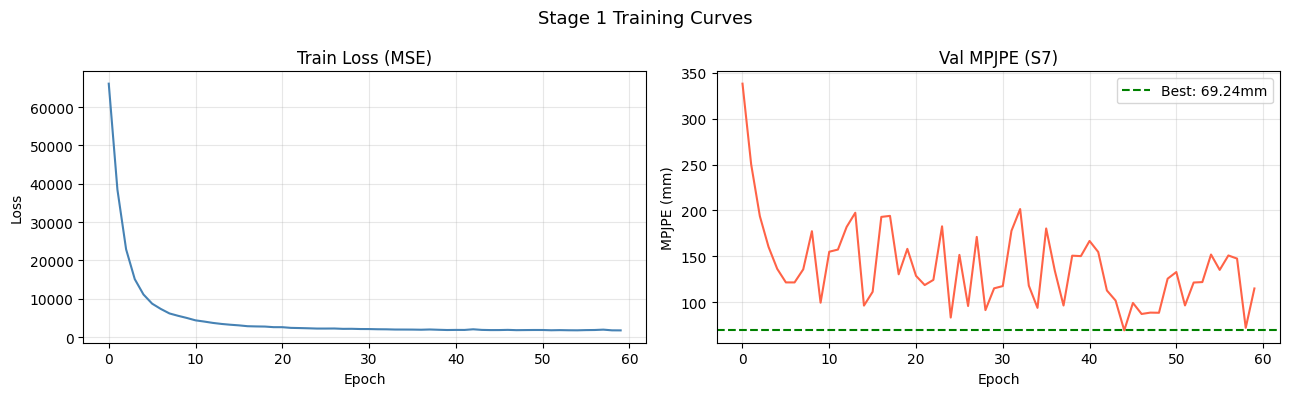

Saved: stage1_curves.png


In [22]:
# ─── Step 10: Stage 1 Learning Curves ────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Stage 1 Training Curves", fontsize=13)

ax1.plot(s1_train_losses, color='steelblue')
ax1.set_title("Train Loss (MSE)"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax1.grid(alpha=0.3)

ax2.plot(s1_val_mpjpes, color='tomato')
ax2.axhline(best_val, linestyle='--', color='green', label=f'Best: {best_val:.2f}mm')
ax2.set_title("Val MPJPE (S7)"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("MPJPE (mm)")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("stage1_curves.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: stage1_curves.png")


In [23]:
# ─── Step 11: Stage 2 — Anatomical Fine-Tuning (30 epochs) ──────────────────
s2_train_ds = MPIINFDataset(BASE_DIR, subjects=[1,2,3,4,5,6,7], num_cams=NUM_CAMS)
s2_test_ds  = MPIINFDataset(BASE_DIR, subjects=[8],              num_cams=NUM_CAMS)

s2_train_loader = DataLoader(s2_train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
s2_test_loader  = DataLoader(s2_test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"Stage 2 train: {len(s2_train_ds):,}  |  test: {len(s2_test_ds):,}")

# Load best Stage 1 weights
s2_model = MultiViewLiftingMLP().to(DEVICE)
s2_model.load_state_dict(torch.load('best_mpi_stage1.pth', map_location=DEVICE))

s2_opt  = torch.optim.Adam(s2_model.parameters(), lr=LR_STAGE2)
s2_sched= torch.optim.lr_scheduler.ReduceLROnPlateau(s2_opt, mode='min', factor=0.5, patience=3)

best_s2 = float('inf')
s2_test_mpjpes = []

print(f"\nStage 2 — {S2_EPOCHS} epochs | lr {LR_STAGE2}")
print(f"{'='*75}")

for epoch in range(S2_EPOCHS):
    s2_model.train()
    el = em = eb = es = 0.0
    for Xb, Yb in s2_train_loader:
        Xb, Yb = Xb.to(DEVICE), Yb.to(DEVICE)
        total, mse, bone, sym = anatomy_loss(s2_model(Xb), Yb)
        s2_opt.zero_grad(); total.backward(); s2_opt.step()
        el += total.item(); em += mse.item(); eb += bone.item(); es += sym.item()

    n = len(s2_train_loader)
    el/=n; em/=n; eb/=n; es/=n

    s2_model.eval()
    tm = 0.0
    with torch.no_grad():
        for Xt, Yt in s2_test_loader:
            Xt, Yt = Xt.to(DEVICE), Yt.to(DEVICE)
            d = torch.norm(s2_model(Xt).view(-1,17,3) - Yt.view(-1,17,3), dim=2)
            tm += d.mean().item()
    avg_t = tm / len(s2_test_loader)
    s2_test_mpjpes.append(avg_t)
    s2_sched.step(avg_t)

    tag = ""
    if avg_t < best_s2:
        best_s2 = avg_t
        torch.save(s2_model.state_dict(), 'best_mpi_stage2.pth')
        tag = "  ⭐"

    print(f"Ep [{epoch+1:>2}/{S2_EPOCHS}]  Loss:{el:.2f}  MSE:{em:.2f}  "
          f"Bone:{eb:.4f}  Sym:{es:.4f}  |  Test MPJPE:{avg_t:.2f}mm{tag}")

print(f"\n✅ Stage 2 done. Best MPJPE on S8: {best_s2:.2f}mm")


  Building dataset for subjects [1, 2, 3, 4, 5, 6, 7]...
    S1/Seq1: 6,416 frames
    S1/Seq2: 12,430 frames
    S2/Seq1: 6,502 frames
    S2/Seq2: 6,081 frames
    S3/Seq1: 12,489 frames
    S3/Seq2: 12,283 frames
    S4/Seq1: 6,171 frames
    S4/Seq2: 6,675 frames
    S5/Seq1: 12,820 frames
    S5/Seq2: 12,312 frames
    S6/Seq1: 6,188 frames
    S6/Seq2: 6,145 frames
    S7/Seq1: 6,239 frames
    S7/Seq2: 6,320 frames
  ✓ Saved: mpi_cache_subs_1_2_3_4_5_6_7_cams4.pt
  ✓ Cache hit: mpi_cache_subs_8_cams4.pt
Stage 2 train: 119,071  |  test: 12,522

Stage 2 — 30 epochs | lr 0.0001
Ep [ 1/30]  Loss:2036.82  MSE:1855.80  Bone:1172.4452  Sym:1275.4099  |  Test MPJPE:67.89mm  ⭐
Ep [ 2/30]  Loss:1996.25  MSE:1828.46  Bone:1094.2694  Sym:1167.3054  |  Test MPJPE:120.45mm
Ep [ 3/30]  Loss:1960.01  MSE:1799.05  Bone:1053.2833  Sym:1112.5674  |  Test MPJPE:62.82mm  ⭐
Ep [ 4/30]  Loss:1923.87  MSE:1767.55  Bone:1027.1422  Sym:1072.1329  |  Test MPJPE:129.87mm
Ep [ 5/30]  Loss:1902.32  MSE:1750.

In [24]:
# ─── Step 12: Final Evaluation ───────────────────────────────────────────────
final = MultiViewLiftingMLP().to(DEVICE)
final.load_state_dict(torch.load('best_mpi_stage2.pth', map_location=DEVICE))
final.eval()

all_dists = []
with torch.no_grad():
    for Xt, Yt in s2_test_loader:
        Xt, Yt = Xt.to(DEVICE), Yt.to(DEVICE)
        d = torch.norm(final(Xt).view(-1,17,3) - Yt.view(-1,17,3), dim=2)
        all_dists.append(d.cpu())

all_dists = torch.cat(all_dists, dim=0)   # (N, 17)
mpjpe     = all_dists.mean().item()

pck = {t: (all_dists < t).float().mean().item()*100 for t in [50,100,150,200]}
per_joint = all_dists.mean(dim=0).numpy()

print("="*55)
print("     FINAL EVALUATION — MPI-INF-3DHP (S8 unseen)")
print("="*55)
print(f"  MPJPE (mean)  : {mpjpe:.2f} mm")
for t,v in pck.items():
    print(f"  PCK@{t}mm     : {v:.2f}%")
print()

df_joints = pd.DataFrame({'Joint': JOINT_NAMES, 'MPJPE (mm)': np.round(per_joint,2)})
print(df_joints.to_string(index=False))
print("="*55)


     FINAL EVALUATION — MPI-INF-3DHP (S8 unseen)
  MPJPE (mean)  : 52.89 mm
  PCK@50mm     : 61.23%
  PCK@100mm     : 87.26%
  PCK@150mm     : 95.11%
  PCK@200mm     : 97.96%

     Joint  MPJPE (mm)
    Pelvis    0.780000
     R.Hip   24.209999
    R.Knee   66.650002
   R.Ankle   74.029999
     L.Hip   24.120001
    L.Knee   63.730000
   L.Ankle   78.300003
     Spine   21.940001
    Thorax   37.439999
      Neck   41.240002
      Head   86.970001
L.Shoulder   52.389999
   L.Elbow   71.589996
   L.Wrist   73.309998
R.Shoulder   45.639999
   R.Elbow   67.699997
   R.Wrist   69.139999


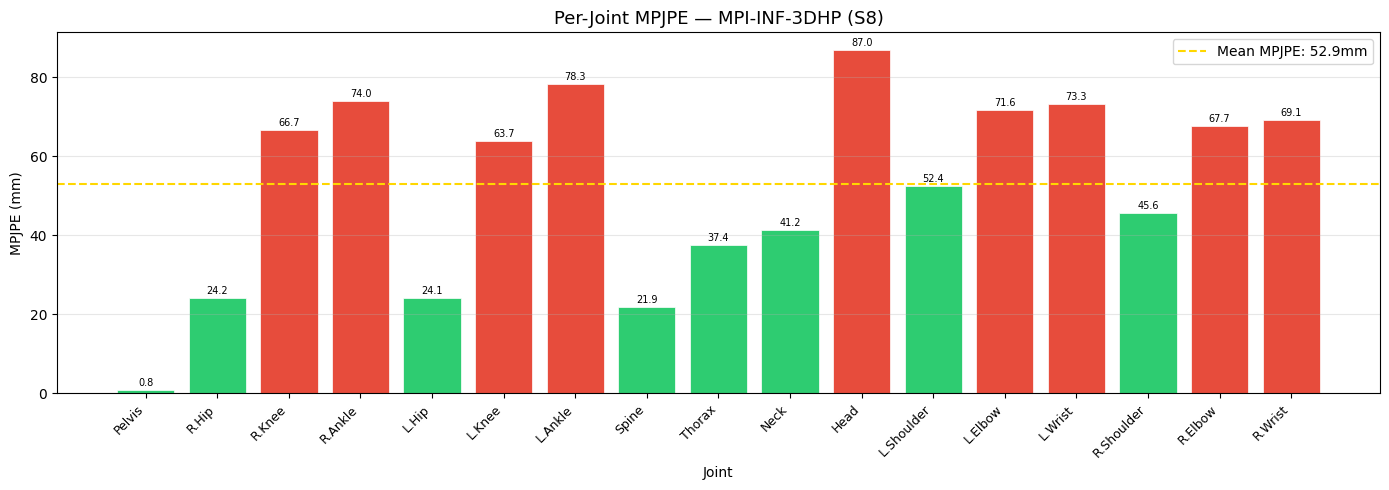

Saved: per_joint_mpjpe.png


In [25]:
# ─── Step 13: Per-Joint MPJPE Bar Chart ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))
colors  = ['#E74C3C' if v > mpjpe else '#2ECC71' for v in per_joint]
bars    = ax.bar(JOINT_NAMES, per_joint, color=colors, edgecolor='white', linewidth=0.5)
ax.axhline(mpjpe, color='gold', linestyle='--', linewidth=1.5, label=f'Mean MPJPE: {mpjpe:.1f}mm')
ax.set_title("Per-Joint MPJPE — MPI-INF-3DHP (S8)", fontsize=13)
ax.set_ylabel("MPJPE (mm)")
ax.set_xlabel("Joint")
plt.xticks(rotation=45, ha='right', fontsize=9)
ax.legend()
ax.grid(axis='y', alpha=0.3)

for bar, val in zip(bars, per_joint):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{val:.1f}', ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig("per_joint_mpjpe.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: per_joint_mpjpe.png")


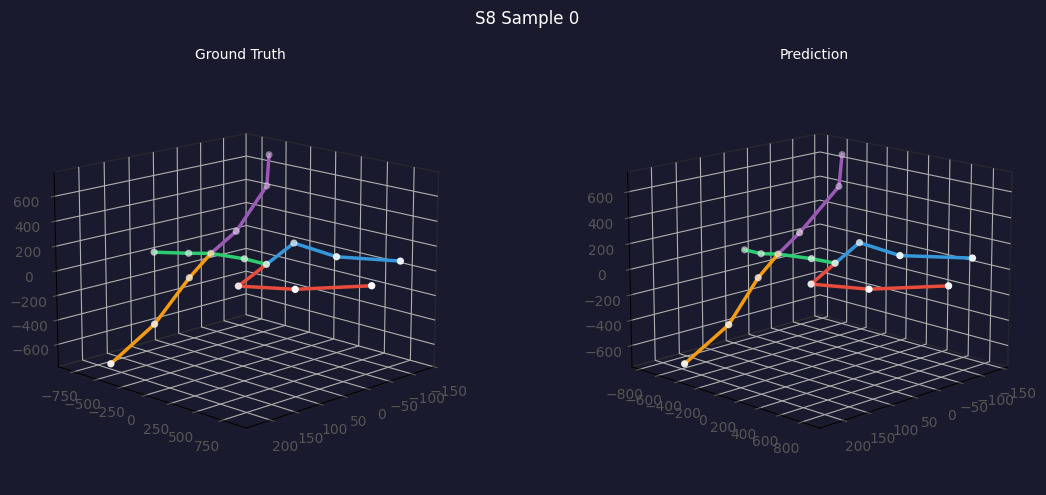

Saved: skeleton_sample_0.png


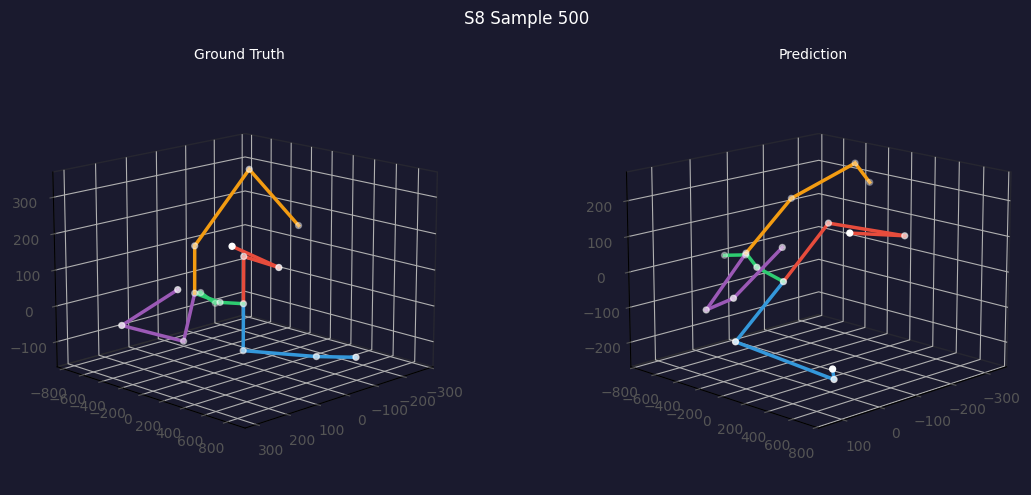

Saved: skeleton_sample_500.png


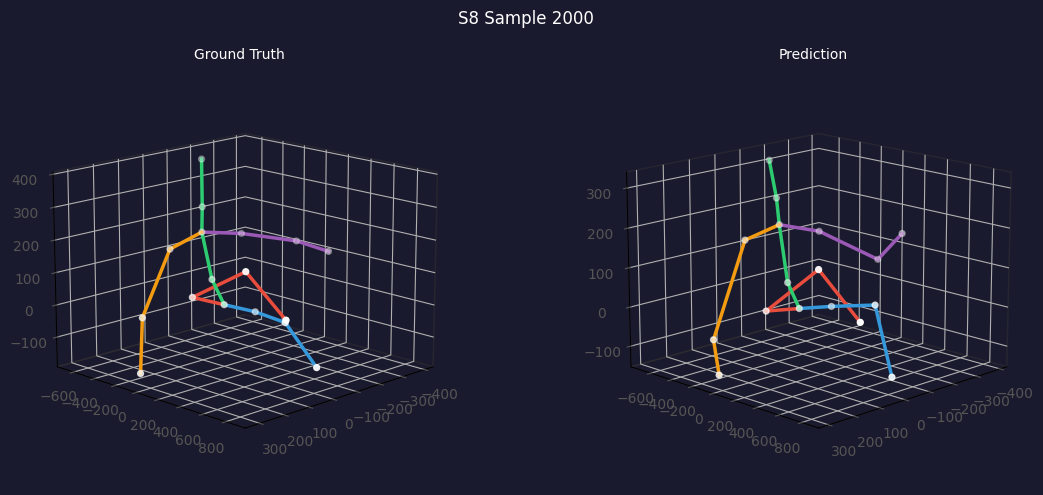

Saved: skeleton_sample_2000.png


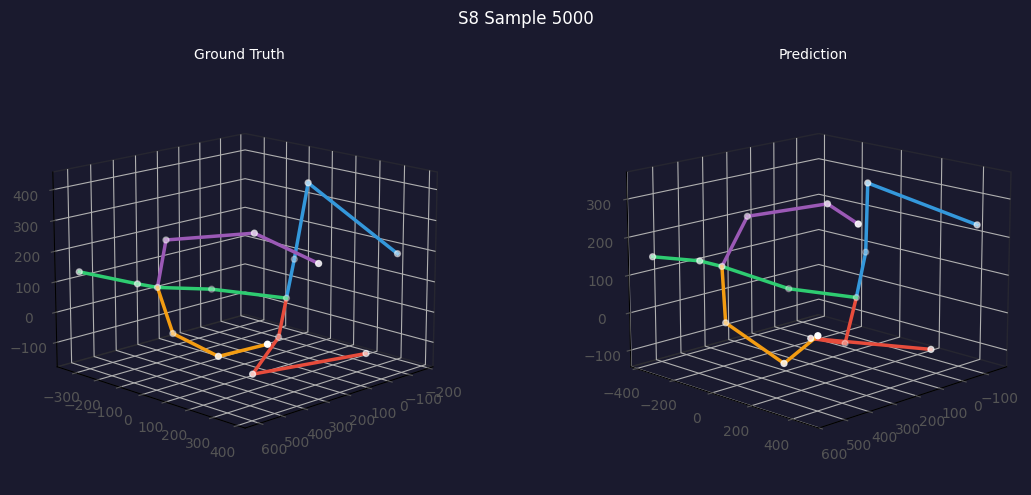

Saved: skeleton_sample_5000.png


In [26]:
# ─── Step 14: 3D Skeleton Visualization ──────────────────────────────────────
BONE_COLORS_MAP = (
    ['#E74C3C']*3 + ['#3498DB']*3 + ['#2ECC71']*4 +
    ['#9B59B6']*3 + ['#F39C12']*3
)

def plot_skeleton(gt, pred, title=""):
    fig  = plt.figure(figsize=(12, 5), facecolor='#1a1a2e')
    fig.suptitle(title, color='white', fontsize=12)
    for col, (data, label) in enumerate([(gt,'Ground Truth'),(pred,'Prediction')]):
        ax = fig.add_subplot(1, 2, col+1, projection='3d')
        ax.set_facecolor('#1a1a2e')
        ax.set_title(label, color='white', fontsize=10)
        ax.tick_params(colors='#555')
        for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
            pane.fill = False; pane.set_edgecolor('#333')
        for bi, (i,j) in enumerate(BONES):
            ax.plot([data[i,0],data[j,0]],[data[i,1],data[j,1]],[data[i,2],data[j,2]],
                    c=BONE_COLORS_MAP[bi], lw=2.5)
        ax.scatter(data[:,0],data[:,1],data[:,2], c='white', s=18, zorder=5)
        ax.view_init(elev=15, azim=45)
    plt.tight_layout()
    return fig

final.eval()
for idx in [0, 500, 2000, 5000]:
    X, Y = s2_test_ds[idx]
    with torch.no_grad():
        pred = final(X.unsqueeze(0).to(DEVICE)).cpu().view(17,3).numpy()
    gt = Y.view(17,3).numpy()
    fig = plot_skeleton(gt, pred, title=f"S8 Sample {idx}")
    fig.savefig(f"skeleton_sample_{idx}.png", dpi=120, bbox_inches='tight', facecolor='#1a1a2e')
    plt.show()
    print(f"Saved: skeleton_sample_{idx}.png")


In [27]:
# ─── Step 15: FYP Results Summary ────────────────────────────────────────────
summary = pd.DataFrame({
    "Metric": [
        "Dataset", "Train Subjects", "Val Subject", "Test Subject (unseen)",
        "Total Train Samples", "Architecture", "Parameters",
        "Input Dim", "Output Dim",
        "Stage 1 Best Val MPJPE", "Stage 2 Final MPJPE (S8)",
        "PCK@50mm","PCK@100mm","PCK@150mm","PCK@200mm",
    ],
    "Value": [
        "MPI-INF-3DHP", "S1–S6", "S7", "S8",
        f"{len(s2_train_ds):,}", "Deep Residual MLP (4 ResBlocks, 1024 hidden)", f"{total:,}",
        "136  (4 cams × 17 joints × 2)", "51  (17 joints × 3)",
        f"{best_val:.2f} mm", f"{best_s2:.2f} mm",
        f"{pck[50]:.2f}%", f"{pck[100]:.2f}%", f"{pck[150]:.2f}%", f"{pck[200]:.2f}%",
    ]
})

print("="*62)
print("         FYP FINAL RESULTS — MPI-INF-3DHP")
print("="*62)
print(summary.to_string(index=False))
print("="*62)
summary.to_csv("fyp_results_summary.csv", index=False)
print("\nSaved: fyp_results_summary.csv")


         FYP FINAL RESULTS — MPI-INF-3DHP
                  Metric                                        Value
                 Dataset                                 MPI-INF-3DHP
          Train Subjects                                        S1–S6
             Val Subject                                           S7
   Test Subject (unseen)                                           S8
     Total Train Samples                                      119,071
            Architecture Deep Residual MLP (4 ResBlocks, 1024 hidden)
              Parameters                          1,890.7696533203125
               Input Dim                136  (4 cams × 17 joints × 2)
              Output Dim                          51  (17 joints × 3)
  Stage 1 Best Val MPJPE                                     69.24 mm
Stage 2 Final MPJPE (S8)                                     49.76 mm
                PCK@50mm                                       61.23%
               PCK@100mm                        